In [1]:
import os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import arviz as az

import jax
import jax.numpy as jnp
from jax import random
from jax import config as jax_config
jax_config.update("jax_enable_x64", True)

import numpyro
import numpyro.distributions as dist
from numpyro.infer import NUTS, MCMC
from numpyro.infer.initialization import init_to_uniform

from astropy.constants import iau2015 as const
from astropy import units

In [2]:
ROOT = Path("/global/homes/z/zhaozhon/project")
sys.path.insert(0, str(ROOT / "src"))

from y3pipe.qlf import ln_likelihood_bin

DATA = ROOT / "data" / "processed"
SPLT = DATA / "splits"
OUT  = ROOT / "results" / "mcmc" / "notebook_tests"
OUT.mkdir(parents=True, exist_ok=True)

print("JAX backend:", jax.default_backend())
print("Devices:", jax.devices())

JAX backend: gpu
Devices: [CudaDevice(id=0)]


In [3]:
BINS = {
    1: (2.3, 2.4),
    2: (2.4, 2.5),
    3: (2.5, 2.6),
    4: (2.6, 2.8),
}

def fit_sigma_order1(idx=3, case="all", m_ref=22.0, nbins=20, min_per_bin=20):
    x = load_case(idx=idx, case=case)

    m = np.asarray(x["m"])
    sigma_m = np.asarray(x["sigma_m"])
    y = np.log10(sigma_m)

    edges = np.linspace(m.min(), m.max(), nbins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    xm, ym, wn = [], [], []
    for i in range(nbins):
        sel = (m >= edges[i]) & (m < edges[i+1])
        n = sel.sum()
        if n < min_per_bin:
            continue
        xm.append(centers[i])
        ym.append(np.median(y[sel]))
        wn.append(np.sqrt(n))

    xm = np.asarray(xm)
    ym = np.asarray(ym)
    wn = np.asarray(wn)

    coeff = np.polyfit(xm - m_ref, ym, deg=1, w=wn)
    return coeff, xm, ym
    
def natlog_bounds():
    ln10 = np.log(10.0)

    # keep your current Nphi convention
    logN_lo, logN_hi = 0.0 * ln10, 10.0 * ln10

    # log_Lstar = ln(Lstar / Lbol0)
    lnLbol0 = np.log(const.L_bol0.to(units.erg / units.s).value)
    logL_lo = 44.0 * ln10 - lnLbol0
    logL_hi = 47.5 * ln10 - lnLbol0

    return logN_lo, logN_hi, logL_lo, logL_hi


def load_case(idx=3, case="all"):
    zmin, zmax = BINS[idx]
    tag = f"bin{idx}_z{zmin}-{zmax}"

    d = np.load(DATA / f"y3_bin{idx}_z{zmin}-{zmax}_arrays.npz")
    s = np.load(SPLT / f"{tag}_split.npz")

    m       = d["apr_mag_r"].astype(np.float64)
    sigma_m = d["sigma_m"].astype(np.float64)
    k       = d["k"].astype(np.float64)
    sigma_k = d["sigma_k"].astype(np.float64)
    mu      = d["mu"].astype(np.float64)

    if case == "all":
        use = s["all"].astype(bool)
    elif case == "upper":
        use = s["upper"].astype(bool)
    elif case == "lower":
        use = s["lower"].astype(bool)
    else:
        raise ValueError(f"Unknown case: {case}")

    return {
        "tag": tag,
        "case": case,
        "zmin": zmin,
        "zmax": zmax,
        "m": jnp.asarray(m[use]),
        "sigma_m": jnp.asarray(sigma_m[use]),
        "k": jnp.asarray(k[use]),
        "sigma_k": jnp.asarray(sigma_k[use]),
        "mu": jnp.asarray(mu[use]),
        "N": int(use.sum()),
    }

In [4]:
def run_mcmc_case(idx=2, case="all", order=1, sigma_coeff=None, m_ref=22.0,
                  num_warmup=2000, num_samples=2000, num_chains=4,
                  seed=12345, target_accept=0.9):

    x = load_case(idx=idx, case=case)

    like = ln_likelihood_bin(
        sigma_m=x["sigma_m"],
        k=x["k"],
        sigma_k=x["sigma_k"],
        zmin=x["zmin"],
        zmax=x["zmax"],
        order=order,
        sigma_coeff=sigma_coeff,
        mu=None,          # constant mu(z_center)
        m_ref=m_ref,
    )

    def model():
        # weak Gaussian prior on m0
        # m0 = numpyro.sample("m0", dist.TruncatedNormal(loc=21.8, scale=0.7, low=20.0, high=24.0))
        m0 = numpyro.sample("m0",dist.Uniform(20,24))
        b  = numpyro.sample("b", dist.Uniform(1.0, 3.0))

        beta = numpyro.sample("beta", dist.Uniform(-7.0, -2.0))
        gap  = numpyro.sample("gap", dist.Uniform(1e-3, 5.0))
        alpha = numpyro.deterministic("alpha", beta + gap)

        # broader normalization / break priors
        log_Nphi  = numpyro.sample("log_Nphi", dist.Uniform(6, 11))
        log_Lstar = numpyro.sample("log_Lstar", dist.Uniform(23.0, 26))

        ll = like(m0, b, x["m"], log_Nphi, log_Lstar, alpha, beta)
        numpyro.factor("log_likelihood", ll)

    nuts = NUTS(
        model,
        target_accept_prob=target_accept,
        init_strategy=init_to_uniform(radius=0.3),
    )

    mcmc = MCMC(
        nuts,
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=num_chains,
        chain_method="sequential",
        progress_bar=True,
    )

    keys = random.split(random.PRNGKey(seed + 1000 * idx), num_chains)
    mcmc.run(keys)
    mcmc.print_summary()

    return x, mcmc

In [5]:
coeff1, xm, ym = fit_sigma_order1(idx=2, case="all")
x, mcmc = run_mcmc_case(
    idx=2,
    case="all",
    order=1,
    sigma_coeff=coeff1,
    m_ref=22.0,
    num_warmup=2000,
    num_samples=2000,
    num_chains=4,
)

sample: 100%|██████████| 4000/4000 [10:38<00:00,  6.26it/s, 255 steps of size 8.45e-03. acc. prob=0.95] 



                 mean       std    median      5.0%     95.0%     n_eff     r_hat
          b      1.58      0.06      1.58      1.48      1.68   2526.88      1.00
       beta     -3.76      0.19     -3.75     -4.06     -3.44   1635.75      1.00
        gap      1.95      0.12      1.94      1.76      2.15   2175.59      1.00
  log_Lstar     25.21      0.18     25.21     24.92     25.50   1584.50      1.00
   log_Nphi      7.79      0.29      7.80      7.30      8.26   1571.39      1.00
         m0     21.97      0.20     21.97     21.65     22.29   1639.70      1.00

Number of divergences: 0


In [6]:
samples = mcmc.get_samples(group_by_chain=False)

outfile = OUT / f"{x['tag']}_{x['case']}_order1_muind_w2000_s2000_c4.npz"
np.savez(
    outfile,
    **{k: np.asarray(v) for k, v in samples.items()},
    bin_index=2,
    case=x["case"],
    order=1,
    mu_mode="per-object",
    zmin=float(x["zmin"]),
    zmax=float(x["zmax"]),
    N_case=int(x["N"]),
)
print("Saved:", outfile)

Saved: /global/homes/z/zhaozhon/project/results/mcmc/notebook_tests/bin2_z2.4-2.5_all_order1_muind_w2000_s2000_c4.npz


In [7]:
samples_chain = mcmc.get_samples(group_by_chain=True)

PARAMS = ["m0", "b", "beta", "gap", "alpha", "log_Lstar", "log_Nphi"]
LABELS = {
    "m0": r"$m_0$",
    "b": r"$b$",
    "beta": r"$\beta$",
    "gap": r"$\Delta$",
    "alpha": r"$\alpha$",
    "log_Lstar": r"$\ln(L_\star/L_{\rm bol,0})$",
    "log_Nphi": r"$\ln \phi_\star$",
}

idata = az.from_dict(
    posterior={p: np.asarray(samples_chain[p]) for p in PARAMS}
)

az.summary(idata, var_names=PARAMS)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
m0,21.970,0.197,21.603,22.337,0.005,0.003,1649.0,2222.0,1.0
b,1.580,0.062,1.465,1.696,0.001,0.001,2719.0,2390.0,1.0
beta,-3.764,0.194,-4.130,-3.404,0.005,0.003,1651.0,2141.0,1.0
gap,1.949,0.122,1.719,2.173,0.003,0.002,2224.0,2611.0,1.0
alpha,-1.816,0.105,-2.019,-1.629,0.003,0.002,1579.0,2112.0,1.0
log_Lstar,25.208,0.176,24.881,25.539,0.004,0.003,1584.0,2007.0,1.0
log_Nphi,7.790,0.292,7.239,8.337,0.007,0.005,1577.0,1961.0,1.0


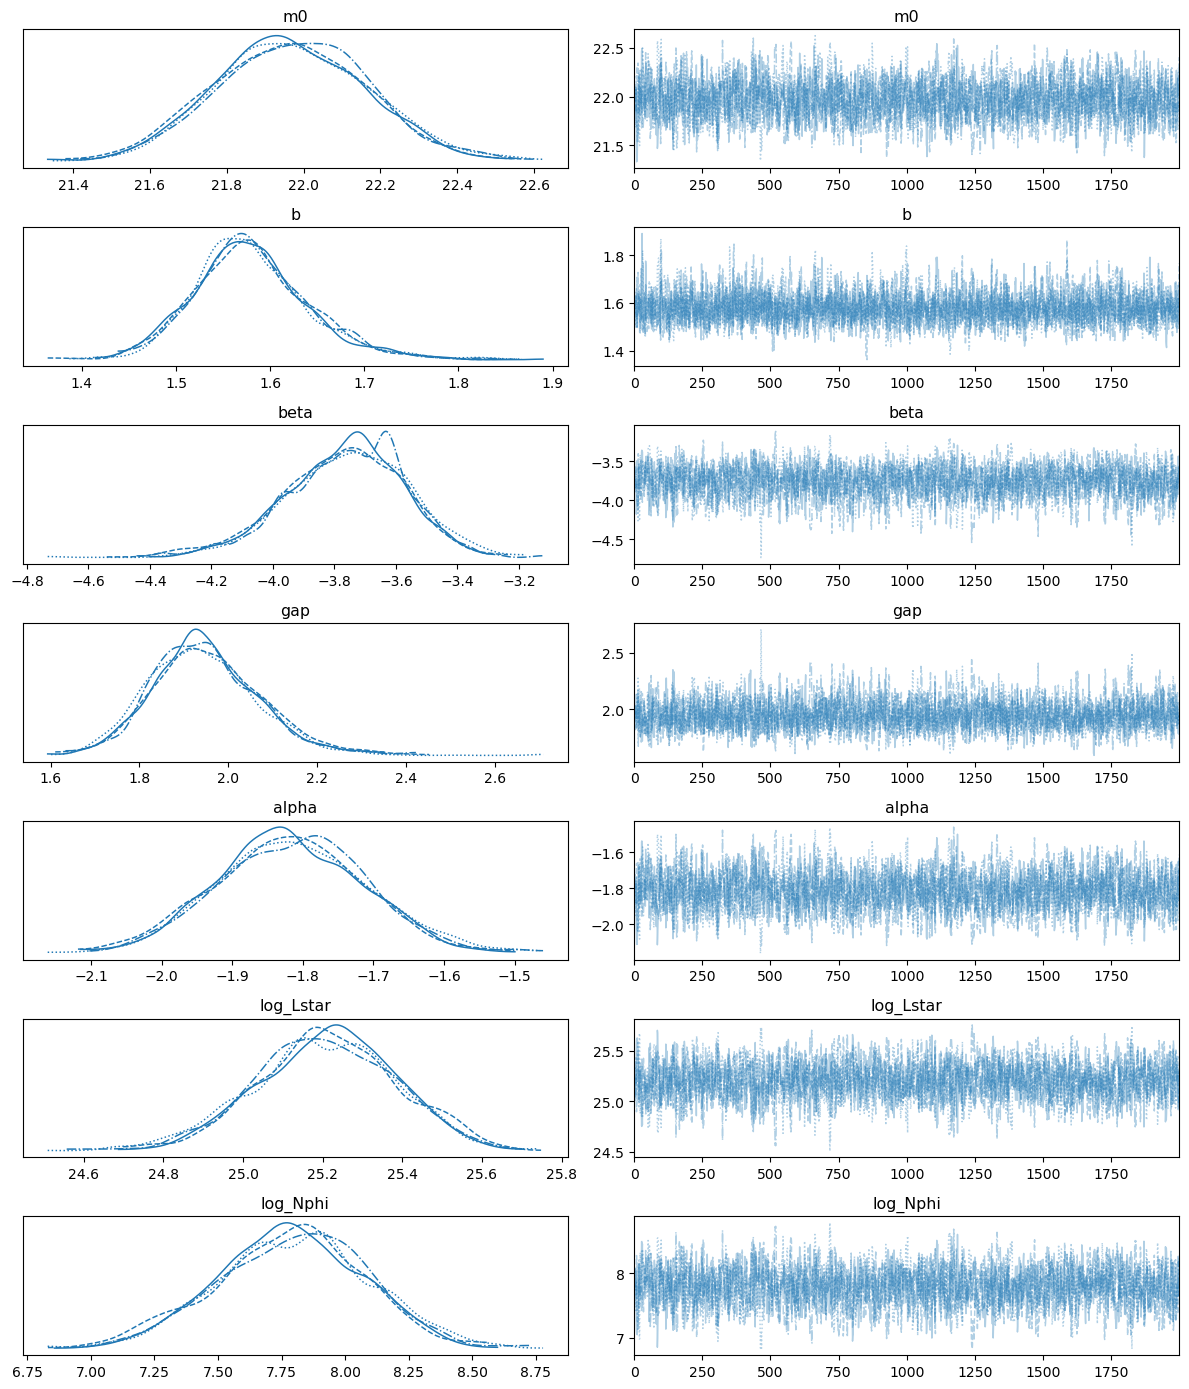

In [8]:
az.plot_trace(idata, var_names=PARAMS, compact=True)
plt.tight_layout()
plt.show()

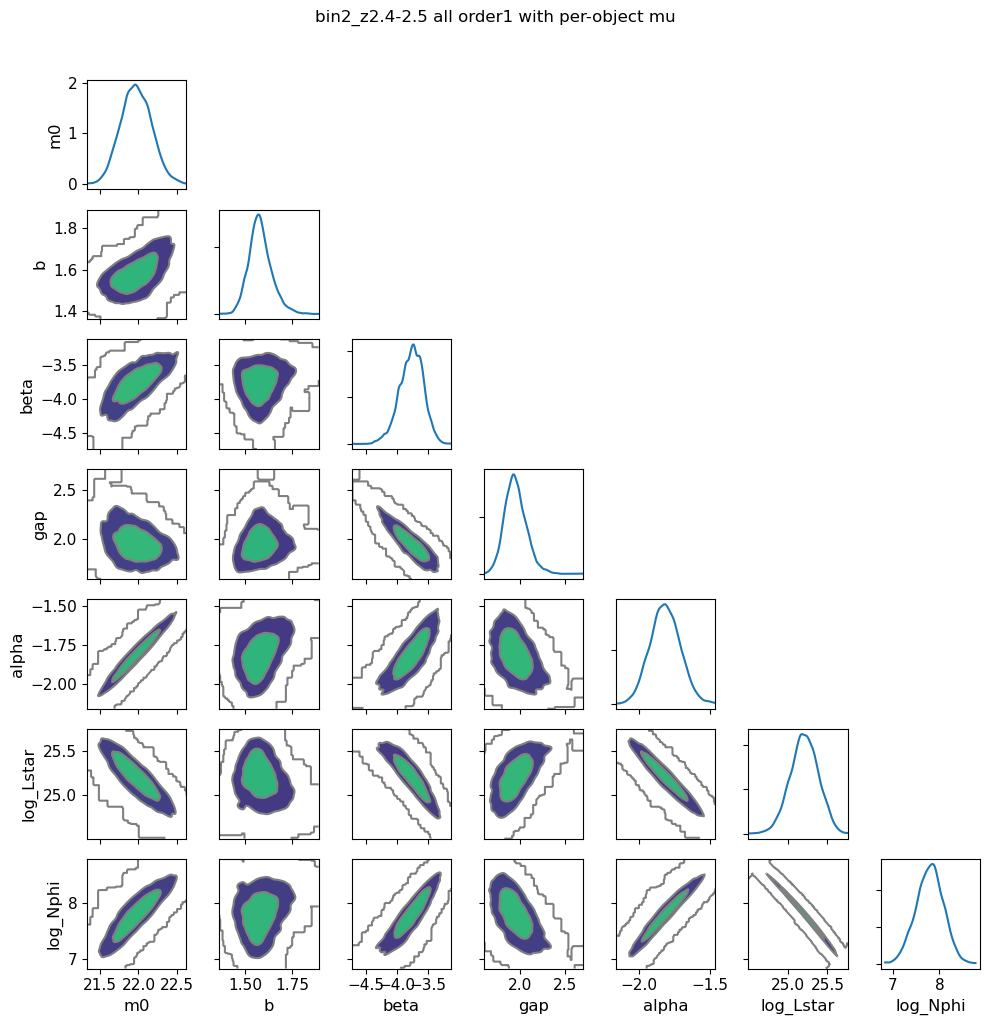

In [9]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

axes = az.plot_pair(
    idata,
    var_names=PARAMS,
    kind="kde",
    marginals=True,
    figsize=(10, 10),
    textsize=11,
    kde_kwargs=dict(
        contour=True,
        fill_last=False,
        hdi_probs=(0.68, 0.95),
    ),
)

plt.suptitle(f"{x['tag']} {x['case']} order1 with per-object mu", y=1.02)
plt.tight_layout()
plt.show()

In [10]:
# flatten chains
logL = np.asarray(samples_chain["log_Lstar"]).reshape(-1)
logN = np.asarray(samples_chain["log_Nphi"]).reshape(-1)

# prior bounds in nat log
logL_lo, logL_hi = 23.0, 26
logN_lo, logN_hi = 6, 11

def edge_test(x, lo, hi, frac=0.02, name="param"):
    width = hi - lo
    eps = frac * width

    near_lo = np.mean(x <= lo + eps)
    near_hi = np.mean(x >= hi - eps)

    print(f"{name}:")
    print(f"  range = [{lo:.3f}, {hi:.3f}]")
    print(f"  edge band width = {eps:.3f} ({100*frac:.1f}% of prior width)")
    print(f"  fraction near lower edge = {near_lo:.5f}")
    print(f"  fraction near upper edge = {near_hi:.5f}")

    # compare density in last edge band to previous interior band
    edge_bin = (x >= hi - eps) & (x <= hi)
    prev_bin = (x >= hi - 2*eps) & (x < hi - eps)
    if prev_bin.sum() > 0:
        ratio_hi = edge_bin.sum() / prev_bin.sum()
        print(f"  upper-edge count / previous-bin count = {ratio_hi:.3f}")
    else:
        print("  upper-edge comparison unavailable")

    edge_bin = (x >= lo) & (x <= lo + eps)
    next_bin = (x > lo + eps) & (x <= lo + 2*eps)
    if next_bin.sum() > 0:
        ratio_lo = edge_bin.sum() / next_bin.sum()
        print(f"  lower-edge count / next-bin count = {ratio_lo:.3f}")
    else:
        print("  lower-edge comparison unavailable")
    print()

edge_test(logL, logL_lo, logL_hi, frac=0.02, name="log_Lstar")
edge_test(logN, logN_lo, logN_hi, frac=0.02, name="log_Nphi")

log_Lstar:
  range = [23.000, 26.000]
  edge band width = 0.060 (2.0% of prior width)
  fraction near lower edge = 0.00000
  fraction near upper edge = 0.00000
  upper-edge comparison unavailable
  lower-edge comparison unavailable

log_Nphi:
  range = [6.000, 11.000]
  edge band width = 0.100 (2.0% of prior width)
  fraction near lower edge = 0.00000
  fraction near upper edge = 0.00000
  upper-edge comparison unavailable
  lower-edge comparison unavailable

